# TAREA 2 - Diplomado ML Facultad de Ingeniería

> Edgar Ulises Moreno Chalico
>
> 318192950

Realiza las siguientes actividades:

1. Compara KNN VS Gaussian NB con cross validation en ambos modelos. ¿Cuál regresa el mejor accuracy?
2. Aplica KNN sobre el dataset de spam. ¿Qué ocurre? ¿Porqué crees que ocurra esto?
3. Agrega visualización de 6 gráficas para obtener insights al dataset de hongos
4. Aplica validación cruzada al dataset de hongos


In [1]:
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import make_scorer, accuracy_score, precision_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

## Actividad 1

Al aplicar validación cruzada de 10 folds, **KNN obtiene el mejor accuracy con 96.67%**, contra **95.33%** de Gaussian NB. Sin embargo, la diferencia es mínima por lo que en la práctica ambos modelos rinden de forma muy similar en el dataset de Iris.

Shape: (150, 5)
=========================== KNN ============================
------------------ Fold and their metrics ------------------
==> Fold 1
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
==> Fold 2
Accuracy: 0.9333
Precision: 0.9444
Recall: 0.9333
==> Fold 3
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
==> Fold 4
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
==> Fold 5
Accuracy: 0.8667
Precision: 0.9048
Recall: 0.8667
==> Fold 6
Accuracy: 0.9333
Precision: 0.9444
Recall: 0.9333
==> Fold 7
Accuracy: 0.9333
Precision: 0.9444
Recall: 0.9333
==> Fold 8
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
==> Fold 9
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
==> Fold 10
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
--------------------- Mean Performance ---------------------
Accuracy: 96.67%
Precision: 97.38%
Recall: 96.67%
======================= Gaussian NB ========================
------------------ Fold and their metrics ------------------
==> Fold 1
Accurac

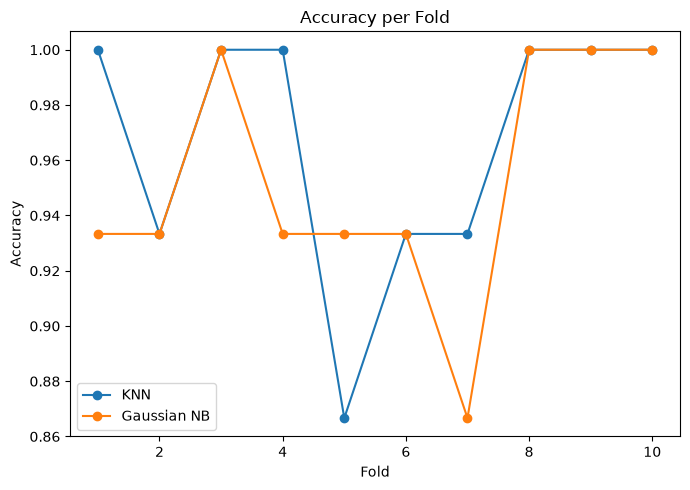

In [2]:
import numpy as np
from sklearn.model_selection import cross_validate
from sklearn.naive_bayes import GaussianNB

df = pd.read_csv("./irisData.csv")
print(f"Shape: {df.shape}")

X = df.iloc[:, 0:4]
y = df.iloc[:, -1]

models = {
    "KNN": KNeighborsClassifier(),
    "Gaussian NB": GaussianNB()
}

scoring_params = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro"
}

all_results = {}

for name, model in models.items():
    results = cross_validate(model, X, y, cv=10, scoring=scoring_params, return_train_score=True, n_jobs=-1)
    all_results[name] = results

    print(f" {name} ".center(60, "="))

    print(" Fold and their metrics ".center(60, "-"))

    for i in range(10):
        print(f"==> Fold {i + 1}")
        print(f"Accuracy: {results['test_accuracy'][i]:.4f}")
        print(f"Precision: {results['test_precision'][i]:.4f}")
        print(f"Recall: {results['test_recall'][i]:.4f}")

    print(" Mean Performance ".center(60, "-"))
    print(f"Accuracy: {np.mean(results['test_accuracy']) * 100:.2f}%")
    print(f"Precision: {np.mean(results['test_precision']) * 100:.2f}%")
    print(f"Recall: {np.mean(results['test_recall']) * 100:.2f}%")

plt.figure(figsize=(7, 5))
for name, results in all_results.items():
    plt.plot(range(1, 11), results["test_accuracy"], marker="o", label=name)
plt.title("Accuracy per Fold")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()

plt.show()

## Actividad 2

El modelo arroja un 91.30% de accuracy, y en la matriz de confusión se puede observar que los mensajes catalogados como _ham_ son los más acertados, sin embargo, por la cantidad de mensajes de tipo _ham_ vs los mensajes de _spam_ los vecinos más cercanos siempre casi siempre serán _ham_, además, la distancia no es lo más adecuado para analizar texto ya que esta depende del largo del mensaje.

### Revisión del recall

El recall indica, de todos los mensajes que realmente pertenecen a una clase, cuántos detectó el modelo:

- **Recall de _ham_: 100%**, los 966 mensajes _ham_ del conjunto de prueba se clasificaron correctamente.
- **Recall de _spam_: 34.90%**, de los 149 mensajes de _spam_ solo 52 fueron detectados y los otros 97 se clasificaron como _ham_.

Esto muestra que el 91.30% de accuracy es engañoso: como el 86.6% de los mensajes son _ham_, un modelo que siempre respondiera _ham_ ya obtendría arriba del 80% de accuracy. KNN solo supera ese valor por poco y deja pasar casi 2 de cada 3 mensajes de _spam_, que es justamente la clase que interesa detectar. Por otro lado, la precisión de _spam_ es de 100%, es decir, cuando KNN marca un mensaje como _spam_ siempre acierta, pero lo hace muy pocas veces.

Data shape: (5572, 2)
======================== Data info =========================
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   mensaje  5572 non-null   str  
 1   target   5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB
======================= Value counts =======================
target
ham     4825
spam     747
Name: count, dtype: int64
========================[ Results ]=========================
Accuracy: 91.30%
Recall (ham): 100.00%
Recall (spam): 34.90%
================== Classification Report ===================
              precision    recall  f1-score   support

         ham       0.91      1.00      0.95       966
        spam       1.00      0.35      0.52       149

    accuracy                           0.91      1115
   macro avg       0.95      0.67      0.73      1115
weighted avg       0.92      0.91      0.89      1115

 Confusion 

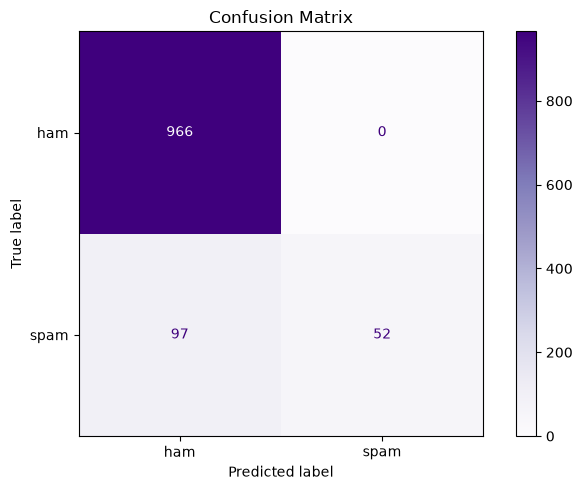

In [3]:
from sklearn.metrics import recall_score, classification_report

df = pd.read_csv('./spam.csv')

print(f"Data shape: {df.shape}")

print(" Data info ".center(60, "="))
df.info()

df["mensaje"] = df["mensaje"].str.strip().str.lower()
df["target"] = df["target"].str.strip().str.lower()

print(" Value counts ".center(60, "="))
print(df["target"].value_counts())

X = df["mensaje"]
Y = df["target"]

# Generación de los sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0, stratify=Y)

model = Pipeline([("vector", CountVectorizer(binary=True)), ("classifier", KNeighborsClassifier())])

print(f"[ Results ]".center(60, "="))

model.fit(X_train, Y_train)

y_pred = model.predict(X_test)

acc = accuracy_score(Y_test, y_pred)
print(f"Accuracy: {acc * 100:.2f}%")

# Recall: de todos los mensajes que realmente son de cada clase, cuántos detectó el modelo
recall_ham = recall_score(Y_test, y_pred, pos_label="ham")
recall_spam = recall_score(Y_test, y_pred, pos_label="spam")
print(f"Recall (ham): {recall_ham * 100:.2f}%")
print(f"Recall (spam): {recall_spam * 100:.2f}%")

print(" Classification Report ".center(60, "="))
print(classification_report(Y_test, y_pred, labels=["ham", "spam"], zero_division=0))

print(" Confusion Matrix ")
cm = confusion_matrix(Y_test, y_pred, labels=["ham", "spam"])
print(cm)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["ham", "spam"]).plot(ax=ax, cmap="Purples")

plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


## Actividad 3

[Información del dataset](https://www.kaggle.com/datasets/uciml/mushroom-classification)

In [4]:
import seaborn as sns

df = pd.read_csv("./mushrooms.csv")
print(f"Shape: {df.shape}")

df.head()

Shape: (8124, 23)


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat,class
0,x,s,n,t,p,f,c,n,k,e,...,w,w,p,w,o,p,k,s,u,p
1,x,s,y,t,a,f,c,b,k,e,...,w,w,p,w,o,p,n,n,g,e
2,b,s,w,t,l,f,c,b,n,e,...,w,w,p,w,o,p,n,n,m,e
3,x,y,w,t,p,f,c,n,n,e,...,w,w,p,w,o,p,k,s,u,p
4,x,s,g,f,n,f,w,b,k,t,...,w,w,p,w,o,e,n,a,g,e


### 1. Distribución de clases

Hay 4208 hongos comestibles (`e`) y 3916 venenosos (`p`), por lo que el dataset está balanceado y el accuracy sí es una métrica confiable (a diferencia del dataset de _spam_).

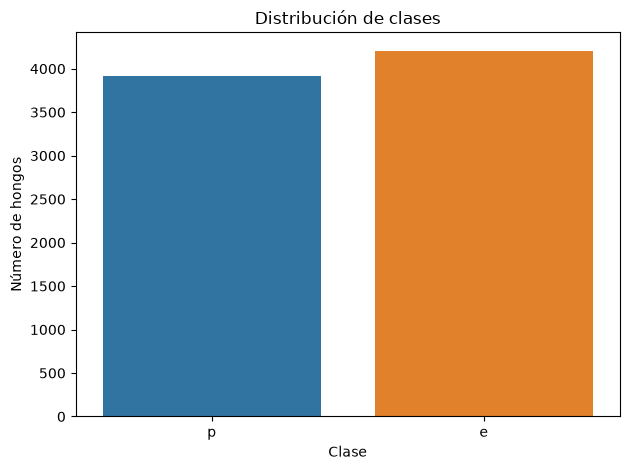

In [5]:
sns.countplot(data=df, x="class", hue="class")
plt.title("Distribución de clases")
plt.xlabel("Clase")
plt.ylabel("Número de hongos")
plt.tight_layout()
plt.show()

### 2. Olor por clase

El olor es la variable más determinante: los hongos con olor a almendra (`a`) o anís (`l`) siempre son comestibles, y los de olor fétido (`f`), a pescado (`y`), especiado (`s`), picante (`p`), a creosota (`c`) o mohoso (`m`) siempre son venenosos. Solo los hongos sin olor (`n`) están mezclados (3408 comestibles y 120 venenosos).

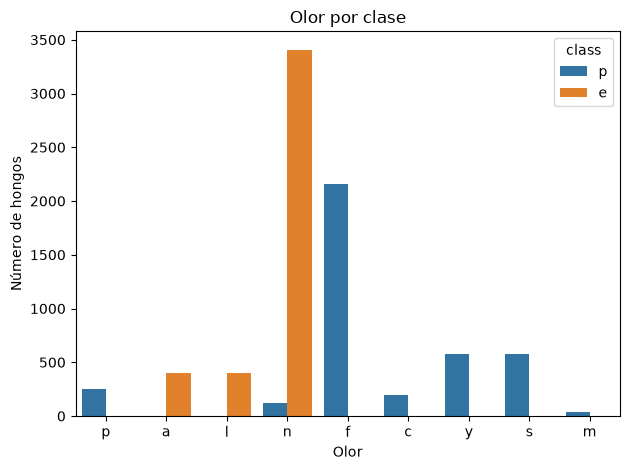

In [6]:
sns.countplot(data=df, x="odor", hue="class")
plt.title("Olor por clase")
plt.xlabel("Olor")
plt.ylabel("Número de hongos")
plt.tight_layout()
plt.show()

### 3. Color de la impresión de esporas por clase

Las esporas color chocolate (`h`) y blanco (`w`) son mayoritariamente venenosas, mientras que las negras (`k`) y cafés (`n`) son mayoritariamente comestibles.

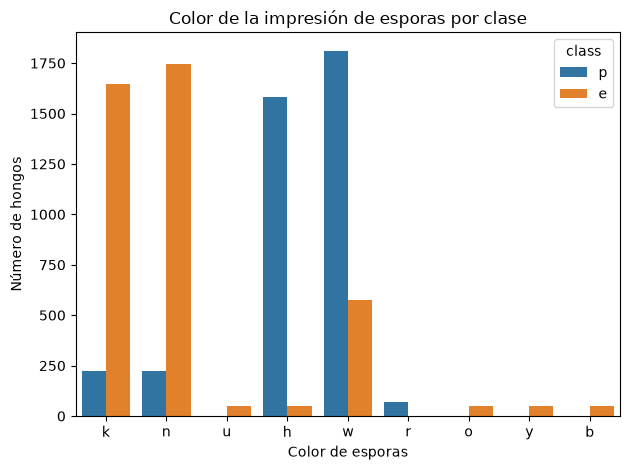

In [7]:
sns.countplot(data=df, x="spore-print-color", hue="class")
plt.title("Color de la impresión de esporas por clase")
plt.xlabel("Color de esporas")
plt.ylabel("Número de hongos")
plt.tight_layout()
plt.show()

### 4. Tamaño de las láminas por clase

Los hongos con láminas angostas (`n`) son en su mayoría venenosos (~89%), mientras que los de láminas anchas (`b`) son en su mayoría comestibles.

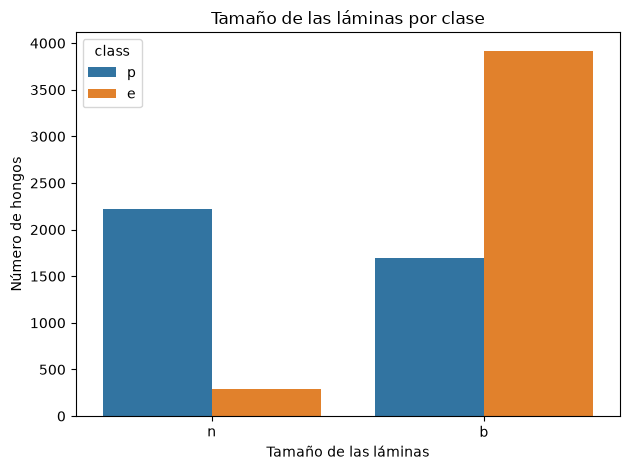

In [8]:
sns.countplot(data=df, x="gill-size", hue="class")
plt.title("Tamaño de las láminas por clase")
plt.xlabel("Tamaño de las láminas")
plt.ylabel("Número de hongos")
plt.tight_layout()
plt.show()

### 5. Color de las láminas vs clase

En el mapa de calor se observa que los hongos con láminas color beige (`b`) siempre son venenosos (1728 registros), mientras que los de láminas cafés (`n`), moradas (`u`) y negras (`k`) son mayoritariamente comestibles.

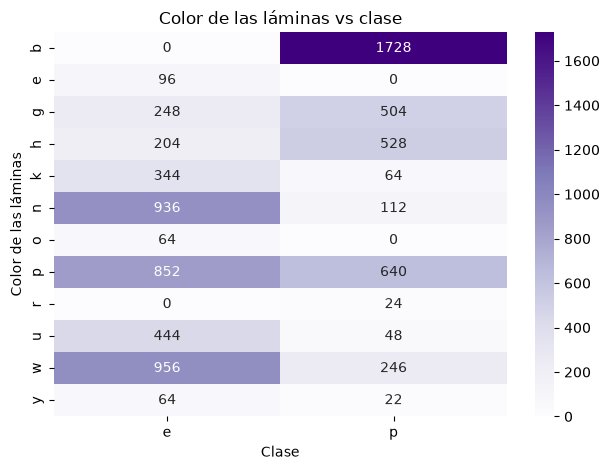

In [9]:
sns.heatmap(pd.crosstab(df["gill-color"], df["class"]), annot=True, fmt="d", cmap="Purples")
plt.title("Color de las láminas vs clase")
plt.xlabel("Clase")
plt.ylabel("Color de las láminas")
plt.tight_layout()
plt.show()

### 6. Hábitat por clase

En senderos (`p`) y hojas (`l`) predominan los hongos venenosos, mientras que en desechos (`w`) y praderas (`m`) predominan los comestibles.

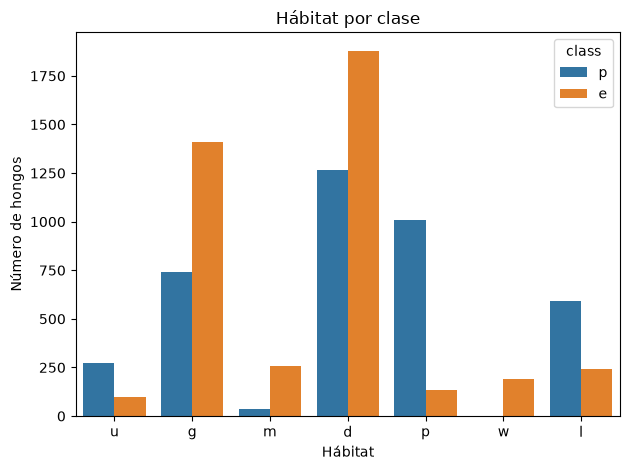

In [10]:
sns.countplot(data=df, x="habitat", hue="class")
plt.title("Hábitat por clase")
plt.xlabel("Hábitat")
plt.ylabel("Número de hongos")
plt.tight_layout()
plt.show()

## Actividad 4

Con las filas mezcladas el modelo obtiene en promedio **92.42% de accuracy**, 94.61% de precisión y 92.26% de recall, con resultados muy parecidos en todos los folds. El accuracy de entrenamiento es similar al de validación aunque hubo folds con accuracy muy bajo.

Shape of the DataFrame: (8124, 23)
------------------ Fold and their metrics ------------------
==> Fold 1
Accuracy: 0.6335
Precision: 0.7928
Recall: 0.6199
==> Fold 2
Accuracy: 0.8807
Precision: 0.9064
Recall: 0.8763
==> Fold 3
Accuracy: 0.9938
Precision: 0.9941
Recall: 0.9936
==> Fold 4
Accuracy: 0.9902
Precision: 0.9907
Recall: 0.9898
==> Fold 5
Accuracy: 0.9643
Precision: 0.9677
Recall: 0.9630
==> Fold 6
Accuracy: 0.9458
Precision: 0.9526
Recall: 0.9439
==> Fold 7
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
==> Fold 8
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
==> Fold 9
Accuracy: 0.8744
Precision: 0.8956
Recall: 0.8788
==> Fold 10
Accuracy: 0.9594
Precision: 0.9611
Recall: 0.9608
--------------------- Mean Performance ---------------------
Accuracy: 92.42%
Precision: 94.61%
Recall: 92.26%


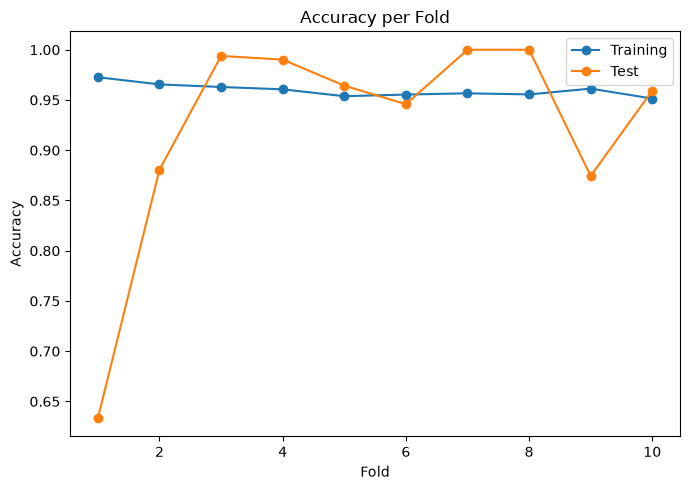

In [11]:
import numpy as np
from sklearn.model_selection import cross_validate
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import OrdinalEncoder

df = pd.read_csv("./mushrooms.csv")
print(f"Shape of the DataFrame: {df.shape}")

X = df.drop(columns=["class"]).copy()
y = df['class']

encoder = OrdinalEncoder()
X_cod = encoder.fit_transform(X).astype(int)

model = CategoricalNB(min_categories=2)

scoring_params = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "recall": "recall_macro"
}

results = cross_validate(model, X_cod, y, cv=10, scoring=scoring_params, return_train_score=True, n_jobs=-1)

print(" Fold and their metrics ".center(60, "-"))

for i in range(10):
    print(f"==> Fold {i + 1}")
    print(f"Accuracy: {results['test_accuracy'][i]:.4f}")
    print(f"Precision: {results['test_precision'][i]:.4f}")
    print(f"Recall: {results['test_recall'][i]:.4f}")

print(" Mean Performance ".center(60, "-"))
print(f"Accuracy: {np.mean(results['test_accuracy']) * 100:.2f}%")
print(f"Precision: {np.mean(results['test_precision']) * 100:.2f}%")
print(f"Recall: {np.mean(results['test_recall']) * 100:.2f}%")

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), results["train_accuracy"], marker="o", label="Training")
plt.plot(range(1, 11), results["test_accuracy"], marker="o", label="Test")
plt.title("Accuracy per Fold")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()